In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, json  # [ADDED 1] os/json are used below to save figures, tables and a results summary

# [ADDED 1] folders for the figures/tables used in the report, a fixed random seed, and a dict that collects key numbers
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/tables', exist_ok=True)
SEED = 42
results = {}

# Set the path to the dataset file
file_path = '/content/RS_Session_263_AU_68_2.csv'
# [CHANGE 1] fallback so the notebook also runs outside Colab (original path is tried first)
if not os.path.exists(file_path):
    for alt in ['RS_Session_263_AU_68_2.csv', 'data/RS_Session_263_AU_68_2.csv']:
        if os.path.exists(alt):
            file_path = alt
            break

try:
    # Load dataset
    pds_df = pd.read_csv(file_path)

    print("--- Raw Dataset Overview ---")
    print(f"Rows: {pds_df.shape[0]}, Columns: {pds_df.shape[1]}\n")
    print("Column Names:", pds_df.columns.tolist())
    print("\n--- First 5 Rows ---")
    display(pds_df.head())
except Exception as e:
    print("Error loading dataset:", e)

--- Raw Dataset Overview ---
Rows: 37, Columns: 16

Column Names: ['Sl. No.', 'States/ UTs', 'Impl. Month', 'Population in lakh (Census 2011)', 'Percentage Coverage - Rural', 'Percentage Coverage - Urban', 'Percentage Coverage - Total', 'Accepted No. of Persons under the Scheme (in Lakh) - Rural', 'Accepted No. of Persons under the Scheme (in Lakh) - Urban', 'Accepted No. of Persons under the Scheme (in Lakh) - Total', 'Ceiling of AAY& PHH (in lakh)', 'Present Coverage (In lakh) - AAY - No. of Families', 'Present Coverage (In lakh) - AAY - No. of Person', 'Present Coverage (In lakh) - Priority - No. of persons', 'Present Coverage (In lakh) - Total persons', 'Present Coverage (In lakh) - % of accepted persons']

--- First 5 Rows ---


,Sl. No.,States/ UTs,Impl. Month,Population in lakh (Census 2011),Percentage Coverage - Rural,Percentage Coverage - Urban,Percentage Coverage - Total,Accepted No. of Persons under the Scheme (in Lakh) - Rural,Accepted No. of Persons under the Scheme (in Lakh) - Urban,Accepted No. of Persons under the Scheme (in Lakh) - Total,Ceiling of AAY& PHH (in lakh),Present Coverage (In lakh) - AAY - No. of Families,Present Coverage (In lakh) - AAY - No. of Person,Present Coverage (In lakh) - Priority - No. of persons,Present Coverage (In lakh) - Total persons,Present Coverage (In lakh) - % of accepted persons
0,1,Andhra Pradesh,Dec-15,493.77,60.96,41.14,54.32,200.20,68.03,268.23,9.09,9.08,23.52,244.70,268.22,100.00
1,2,Arunachal Pradesh,Apr-16,13.83,66.31,51.55,62.95,7.09,1.62,8.71,0.38,0.38,1.50,6.90,8.40,96.53
2,3,Assam,Dec-15,311.69,84.17,60.35,80.82,225.41,26.49,251.90,7.04,6.92,28.08,223.08,251.17,99.71
3,4,Bihar,Mar-14,1038.05,85.12,74.53,83.92,783.74,87.42,871.16,25.01,25.01,125.05,746.11,871.16,100.00
4,5,Chattisgarh,Jan-14,255.40,84.25,59.98,78.61,165.16,35.61,200.77,7.19,7.19,20.42,180.35,200.77,100.00


##  Diagnostic Checks & Data Cleaning
We will inspect the unique values of State/UT names, identify aggregate summary rows (e.g. "Total"), check for missing values, and verify that columns containing numeric values are stored with correct numeric data types.

In [2]:
# 1. Inspect all unique State / UT names to find trailing spaces or 'Total' rows
print("--- Unique States/UTs in Dataset ---")
unique_states = pds_df['States/ UTs'].unique().tolist()
for state in unique_states:
    print(f"'{state}'")

# 2. Check for missing (null) values
print("\n--- Missing Values Per Column ---")
print(pds_df.isnull().sum())

# 3. Check data types of all columns
print("\n--- Column Data Types ---")
print(pds_df.dtypes)

# [ADDED 2] extra checks: duplicate State/UT names and non-numeric columns
print("\n--- Duplicate State/UT names (after stripping spaces) ---")
print(int(pds_df['States/ UTs'].str.strip().duplicated().sum()))
non_numeric = [c for c in pds_df.columns if c not in ['Sl. No.', 'States/ UTs', 'Impl. Month'] and not pd.api.types.is_numeric_dtype(pds_df[c])]
print("Non-numeric columns that should be numeric:", non_numeric)

--- Unique States/UTs in Dataset ---
'Andhra Pradesh'
'Arunachal Pradesh'
'Assam'
'Bihar'
'Chattisgarh'
'Delhi'
'Goa'
'Gujarat'
'Haryana'
'Himachal Pradesh'
'Jharkhand'
'Karnataka'
'Kerala'
'Madhya Pradesh'
'Maharashtra'
'Manipur'
'Meghalaya'
'Mizoram'
'Nagaland'
'Odisha'
'Punjab'
'Rajasthan'
'Sikkim'
'Tamil Nadu'
'Telangana'
'Tripura'
'Uttar Pradesh'
'Uttarakhand'
'West Bengal'
'Andaman and Nicobar'
'Dadra and Nagar Haveli and Daman and Diu'
'Lakshadweep'
'Chandigarh (DBT)'
'Puduchery (DBT)'
'Jammu and Kashmir'
'Ladakh'
'Total'

--- Missing Values Per Column ---
Sl. No.                                                       0
States/ UTs                                                   0
Impl. Month                                                   0
Population in lakh (Census 2011)                              0
Percentage Coverage - Rural                                   0
Percentage Coverage - Urban                                   0
Percentage Coverage - Total                   

## Dataset Cleaning
We remove the summary row (`'Total'`) and clean any whitespace from the `'States/ UTs'` column to ensure high-fidelity mapping and modelling.

The `'Total'` row is an aggregate that repeats the 36 States/UTs, so keeping it would double count; we verify this below before dropping it.

<!-- CHANGE 3: earlier text called the Total row an 'outlier/leverage point'; the correct reason is double counting. Remove this comment. -->

In [3]:
# 1. Strip whitespace from State/UT names
pds_df['States/ UTs'] = pds_df['States/ UTs'].str.strip()

# 2. Drop the aggregate row 'Total'
clean_pds_df = pds_df[pds_df['States/ UTs'] != 'Total'].copy()

print(f"Raw dataset shape: {pds_df.shape}")
print(f"Cleaned dataset shape (without 'Total'): {clean_pds_df.shape}")

# Quick confirmation
print("'Total' row exists in cleaned dataset?", 'Total' in clean_pds_df['States/ UTs'].values)

# [ADDED 3] verify that the 'Total' row really is the sum of the 36 units (this is why it is dropped: double counting)
total_row = pds_df[pds_df['States/ UTs'] == 'Total'].iloc[0]
results['total_row_pop'] = float(total_row['Population in lakh (Census 2011)'])
results['sum_units_pop'] = float(clean_pds_df['Population in lakh (Census 2011)'].sum())
results['total_row_accepted'] = float(total_row['Accepted No. of Persons under the Scheme (in Lakh) - Total'])
results['sum_units_accepted'] = float(clean_pds_df['Accepted No. of Persons under the Scheme (in Lakh) - Total'].sum())
print(f"'Total' row population {results['total_row_pop']:.2f} lakh vs sum of the units {results['sum_units_pop']:.2f} lakh")
print(f"'Total' row accepted persons {results['total_row_accepted']:.2f} lakh vs sum of the units {results['sum_units_accepted']:.2f} lakh")
assert len(clean_pds_df) == 36, "expected 36 States/UTs"
clean_pds_df = clean_pds_df.reset_index(drop=True)   # clean 0..35 index (needed for the diagnostics later)

Raw dataset shape: (37, 16)
Cleaned dataset shape (without 'Total'): (36, 16)
'Total' row exists in cleaned dataset? False
'Total' row population 12103.22 lakh vs sum of the units 12103.22 lakh
'Total' row accepted persons 8134.91 lakh vs sum of the units 8134.94 lakh


## Injecting State 'Need' Indicators
To analyze whether PDS coverage matches actual food-security needs, we introduce two indicators for each of the 36 States/UTs (sources are given in the comments of the next cell):
1. **Poverty Rate (%)**: State-wise Multidimensional Poverty Index (MPI) headcount ratio (NITI Aayog National MPI Baseline Report, 2021; reference period NFHS-4, 2015-16).
2. **Under-5 Childhood Malnutrition (%)**: share of children under 5 who are underweight (weight-for-age), NFHS-5 (2019-21), as tabulated in the Economic Survey 2021-22, Statistical Appendix Table 8.17.

<!-- CHANGE 4: the original text called these 'verified' although the code comments said 'estimate' and the malnutrition values mixed stunting and underweight. Remove this comment. -->

In [4]:
# Define reliable state-wise need indicators matching our 36 States/UTs exactly
# [CHANGE 5] Sources: Poverty_Rate_Pct = NITI Aayog National MPI Baseline Report (2021) headcount ratio; Child_Malnutrition_Pct = % of under-5 children underweight,
# NFHS-5 (2019-21) as tabulated in Economic Survey 2021-22, Statistical Appendix Table 8.17. The earlier values were estimates (mostly stunting) and are replaced.
# Rows marked [CHECK] are not yet verified against the primary table: please check them and delete the marker.
state_need_data = {
    'Andhra Pradesh': {'Poverty_Rate_Pct': 12.3, 'Child_Malnutrition_Pct': 29.6},  # [CHECK] MPI: compare with the NITI Aayog table
    'Arunachal Pradesh': {'Poverty_Rate_Pct': 24.2, 'Child_Malnutrition_Pct': 15.4},  # [CHECK] MPI: compare with the NITI Aayog table
    'Assam': {'Poverty_Rate_Pct': 32.7, 'Child_Malnutrition_Pct': 32.8},  # [CHECK] MPI: compare with the NITI Aayog table
    'Bihar': {'Poverty_Rate_Pct': 51.91, 'Child_Malnutrition_Pct': 41.0},
    'Chattisgarh': {'Poverty_Rate_Pct': 29.9, 'Child_Malnutrition_Pct': 31.3},  # [CHECK] MPI: compare with the NITI Aayog table
    'Delhi': {'Poverty_Rate_Pct': 4.79, 'Child_Malnutrition_Pct': 21.8},
    'Goa': {'Poverty_Rate_Pct': 3.76, 'Child_Malnutrition_Pct': 24.0},  # [CHANGE 5] MPI corrected from 5.9 in the original notebook to the published 3.76
    'Gujarat': {'Poverty_Rate_Pct': 18.6, 'Child_Malnutrition_Pct': 39.7},  # [CHECK] MPI: compare with the NITI Aayog table
    'Haryana': {'Poverty_Rate_Pct': 12.3, 'Child_Malnutrition_Pct': 21.5},  # [CHECK] MPI: compare with the NITI Aayog table
    'Himachal Pradesh': {'Poverty_Rate_Pct': 7.6, 'Child_Malnutrition_Pct': 25.5},  # [CHECK] MPI: compare with the NITI Aayog table
    'Jharkhand': {'Poverty_Rate_Pct': 42.16, 'Child_Malnutrition_Pct': 39.4},
    'Karnataka': {'Poverty_Rate_Pct': 13.2, 'Child_Malnutrition_Pct': 32.9},  # [CHECK] MPI: compare with the NITI Aayog table
    'Kerala': {'Poverty_Rate_Pct': 0.71, 'Child_Malnutrition_Pct': 19.7},
    'Madhya Pradesh': {'Poverty_Rate_Pct': 36.7, 'Child_Malnutrition_Pct': 33.0},  # [CHECK] MPI: compare with the NITI Aayog table
    'Maharashtra': {'Poverty_Rate_Pct': 14.9, 'Child_Malnutrition_Pct': 36.1},  # [CHECK] MPI: compare with the NITI Aayog table
    'Manipur': {'Poverty_Rate_Pct': 16.1, 'Child_Malnutrition_Pct': 13.3},  # [CHECK] MPI: compare with the NITI Aayog table
    'Meghalaya': {'Poverty_Rate_Pct': 32.7, 'Child_Malnutrition_Pct': 26.6},  # [CHECK] MPI: compare with the NITI Aayog table
    'Mizoram': {'Poverty_Rate_Pct': 9.8, 'Child_Malnutrition_Pct': 12.7},  # [CHECK] MPI: compare with the NITI Aayog table
    'Nagaland': {'Poverty_Rate_Pct': 25.2, 'Child_Malnutrition_Pct': 26.9},  # [CHECK] MPI: compare with the NITI Aayog table
    'Odisha': {'Poverty_Rate_Pct': 29.4, 'Child_Malnutrition_Pct': 29.7},  # [CHECK] MPI: compare with the NITI Aayog table
    'Punjab': {'Poverty_Rate_Pct': 5.59, 'Child_Malnutrition_Pct': 16.9},
    'Rajasthan': {'Poverty_Rate_Pct': 29.5, 'Child_Malnutrition_Pct': 27.6},  # [CHECK] MPI: compare with the NITI Aayog table
    'Sikkim': {'Poverty_Rate_Pct': 3.82, 'Child_Malnutrition_Pct': 13.1},
    'Tamil Nadu': {'Poverty_Rate_Pct': 4.89, 'Child_Malnutrition_Pct': 22.0},
    'Telangana': {'Poverty_Rate_Pct': 13.7, 'Child_Malnutrition_Pct': 31.8},  # [CHECK] MPI: compare with the NITI Aayog table
    'Tripura': {'Poverty_Rate_Pct': 16.7, 'Child_Malnutrition_Pct': 25.6},  # [CHECK] MPI: compare with the NITI Aayog table
    'Uttar Pradesh': {'Poverty_Rate_Pct': 37.79, 'Child_Malnutrition_Pct': 32.1},
    'Uttarakhand': {'Poverty_Rate_Pct': 17.7, 'Child_Malnutrition_Pct': 21.0},  # [CHECK] MPI: compare with the NITI Aayog table
    'West Bengal': {'Poverty_Rate_Pct': 21.4, 'Child_Malnutrition_Pct': 32.2},  # [CHECK] MPI: compare with the NITI Aayog table
    'Andaman and Nicobar': {'Poverty_Rate_Pct': 4.3, 'Child_Malnutrition_Pct': 23.7},
    'Dadra and Nagar Haveli and Daman and Diu': {'Poverty_Rate_Pct': 18.85, 'Child_Malnutrition_Pct': 38.7},  # [CHANGE 5] MPI baseline reports Dadra & Nagar Haveli (27.36) and Daman & Diu (6.82) separately; merged value is their Census-2011 population-weighted mean
    'Lakshadweep': {'Poverty_Rate_Pct': 1.82, 'Child_Malnutrition_Pct': 25.8},
    'Chandigarh (DBT)': {'Poverty_Rate_Pct': 5.97, 'Child_Malnutrition_Pct': 20.6},  # [CHANGE 5] MPI corrected from 5.0 in the original notebook to the published 5.97
    'Puduchery (DBT)': {'Poverty_Rate_Pct': 1.72, 'Child_Malnutrition_Pct': 15.3},
    'Jammu and Kashmir': {'Poverty_Rate_Pct': 12.58, 'Child_Malnutrition_Pct': 21.0},  # [CHANGE 5] MPI baseline reports Jammu & Kashmir and Ladakh combined; NFHS-5 value is for J&K excluding Ladakh
    'Ladakh': {'Poverty_Rate_Pct': 12.58, 'Child_Malnutrition_Pct': 9.1},  # [CHECK] underweight: confirm in the NFHS-5 fact sheet | [CHANGE 5] MPI: combined J&K+Ladakh baseline value assigned to both. Underweight 9.1 is as printed in the source table but looks low - confirm in the NFHS-5 Ladakh fact sheet
}

# Map metrics to clean_pds_df
clean_pds_df['Poverty_Rate_Pct'] = clean_pds_df['States/ UTs'].map(lambda x: state_need_data.get(x, {}).get('Poverty_Rate_Pct', np.nan))
clean_pds_df['Child_Malnutrition_Pct'] = clean_pds_df['States/ UTs'].map(lambda x: state_need_data.get(x, {}).get('Child_Malnutrition_Pct', np.nan))

# Validate merging results
print("Missing Need Metrics:")
print(clean_pds_df[['States/ UTs', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct']].isnull().sum())

print("\nClean Dataframe Snapshot with Need Variables:")
display(clean_pds_df[['States/ UTs', 'Population in lakh (Census 2011)', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct']].head())

# [ADDED 4] provenance bookkeeping: values still to be verified, and units whose value needed an adjustment (used in the report)
results['mpi_unverified'] = ['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Rajasthan', 'Telangana', 'Tripura', 'Uttarakhand', 'West Bengal']
results['mal_unverified'] = ['Ladakh']
results['adjustments'] = {
    'Goa': 'MPI corrected from 5.9 in the first version to the published 3.76',
    'Chandigarh (DBT)': 'MPI corrected from 5.0 in the first version to the published 5.97',
    'Dadra and Nagar Haveli and Daman and Diu': 'MPI baseline reports Dadra and Nagar Haveli (27.36) and Daman and Diu (6.82) separately; the merged value is their Census-2011 population-weighted mean',
    'Jammu and Kashmir': 'MPI baseline reports Jammu and Kashmir and Ladakh combined; NFHS-5 underweight is for J and K excluding Ladakh',
    'Ladakh': 'MPI: combined J and K plus Ladakh baseline value assigned to both; the underweight value should be confirmed in the NFHS-5 Ladakh fact sheet'
}
assert clean_pds_df[['Poverty_Rate_Pct', 'Child_Malnutrition_Pct']].notna().all().all(), "unmatched State/UT names"
print("\nMPI values still to be verified:", results['mpi_unverified'])
print("Underweight values still to be verified:", results['mal_unverified'])

Missing Need Metrics:
States/ UTs               0
Poverty_Rate_Pct          0
Child_Malnutrition_Pct    0
dtype: int64

Clean Dataframe Snapshot with Need Variables:


,States/ UTs,Population in lakh (Census 2011),Poverty_Rate_Pct,Child_Malnutrition_Pct
0,Andhra Pradesh,493.77,12.30,29.6
1,Arunachal Pradesh,13.83,24.20,15.4
2,Assam,311.69,32.70,32.8
3,Bihar,1038.05,51.91,41.0
4,Chattisgarh,255.40,29.90,31.3



MPI values still to be verified: ['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Chattisgarh', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Rajasthan', 'Telangana', 'Tripura', 'Uttarakhand', 'West Bengal']
Underweight values still to be verified: ['Ladakh']


## Ratio Features for the AAY and PHH Tiers
The problem statement asks us to compare each State's **AAY** (Antyodaya) and **PHH** (Priority Household) coverage with population, poverty and child under-nutrition. We therefore derive ratio features from the AAY and Priority columns and check the source table for internal consistency.

<!-- ADDED 5: new section. Remove this comment. -->

In [5]:
# [ADDED 5] short names used by the new cells
STATE, POP = 'States/ UTs', 'Population in lakh (Census 2011)'
Y, P, M = 'Percentage Coverage - Total', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct'
AAYP = 'Present Coverage (In lakh) - AAY - No. of Person'
AAYF = 'Present Coverage (In lakh) - AAY - No. of Families'
PHHP = 'Present Coverage (In lakh) - Priority - No. of persons'
TOTP = 'Present Coverage (In lakh) - Total persons'
ACC = 'Accepted No. of Persons under the Scheme (in Lakh) - Total'
for c in (AAYP, AAYF, PHHP, TOTP, ACC):
    assert c in clean_pds_df.columns, f"column missing: {c}"

clean_pds_df['AAY_per100'] = clean_pds_df[AAYP] / clean_pds_df[POP] * 100        # AAY persons per 100 population
clean_pds_df['PHH_per100'] = clean_pds_df[PHHP] / clean_pds_df[POP] * 100        # Priority-household persons per 100 population
clean_pds_df['AAY_share'] = clean_pds_df[AAYP] / (clean_pds_df[AAYP] + clean_pds_df[PHHP]) * 100   # share of covered persons that are AAY (%)
clean_pds_df['AAY_size'] = clean_pds_df[AAYP] / clean_pds_df[AAYF].replace(0, np.nan)             # implied persons per AAY family
clean_pds_df['LogPop'] = np.log(clean_pds_df[POP])

# consistency checks between the columns of the source table
results['cov_recompute_maxdiff'] = float((clean_pds_df[ACC] / clean_pds_df[POP] * 100 - clean_pds_df[Y]).abs().max())
results['tier_sum_maxdiff'] = float((clean_pds_df[AAYP] + clean_pds_df[PHHP] - clean_pds_df[TOTP]).abs().max())
results['n_size_exactly5'] = int(((clean_pds_df['AAY_size'] - 5).abs() < 0.01).sum())
results['n_zero_aay_families'] = int((clean_pds_df[AAYF] <= 0).sum())
results['aay_size_min'], results['aay_size_max'] = float(clean_pds_df['AAY_size'].min()), float(clean_pds_df['AAY_size'].max())
print(f"Coverage % recomputed as accepted/population: max abs difference {results['cov_recompute_maxdiff']:.3f} pp")
print(f"AAY + PHH persons vs total present persons: max abs difference {results['tier_sum_maxdiff']:.3f} lakh")
print(f"Implied persons per AAY family: min {results['aay_size_min']:.2f}, max {results['aay_size_max']:.2f}; "
      f"{results['n_size_exactly5']} unit(s) at exactly 5.00; {results['n_zero_aay_families']} unit(s) with zero AAY families at published precision")
display(clean_pds_df[[STATE, 'AAY_per100', 'PHH_per100', 'AAY_share', 'AAY_size']].round(2).head(8))

Coverage % recomputed as accepted/population: max abs difference 0.205 pp
AAY + PHH persons vs total present persons: max abs difference 0.010 lakh
Implied persons per AAY family: min 2.46, max 5.00; 1 unit(s) at exactly 5.00; 1 unit(s) with zero AAY families at published precision


,States/ UTs,AAY_per100,PHH_per100,AAY_share,AAY_size
0,Andhra Pradesh,4.76,49.56,8.77,2.59
1,Arunachal Pradesh,10.85,49.89,17.86,3.95
2,Assam,9.01,71.57,11.18,4.06
3,Bihar,12.05,71.88,14.35,5.00
4,Chattisgarh,8.00,70.61,10.17,2.84
5,Delhi,1.66,41.78,3.82,4.03
6,Goa,3.16,33.33,8.65,3.83
7,Gujarat,5.88,52.34,10.11,4.60


## Correlation Analysis
Before building our models, we evaluate the linear correlation between our objective need indicators (`Poverty_Rate_Pct`, `Child_Malnutrition_Pct`) and actual PDS metrics like total coverage percentage (`Percentage Coverage - Total`) and total accepted beneficiaries.

--- Correlation Matrix Between Need and Coverage Metrics ---


,Population in lakh (Census 2011),Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,PHH_per100,AAY_per100,AAY_share
Population in lakh (Census 2011),1.000,0.474,0.536,0.328,0.438,0.061,-0.182
Poverty_Rate_Pct,0.474,1.000,0.605,0.779,0.799,0.419,-0.111
Child_Malnutrition_Pct,0.536,0.605,1.000,0.337,0.377,0.098,-0.125
Percentage Coverage - Total,0.328,0.779,0.337,1.000,0.938,0.514,-0.174
PHH_per100,0.438,0.799,0.377,0.938,1.000,0.415,-0.287
AAY_per100,0.061,0.419,0.098,0.514,0.415,1.000,0.697
AAY_share,-0.182,-0.111,-0.125,-0.174,-0.287,0.697,1.000


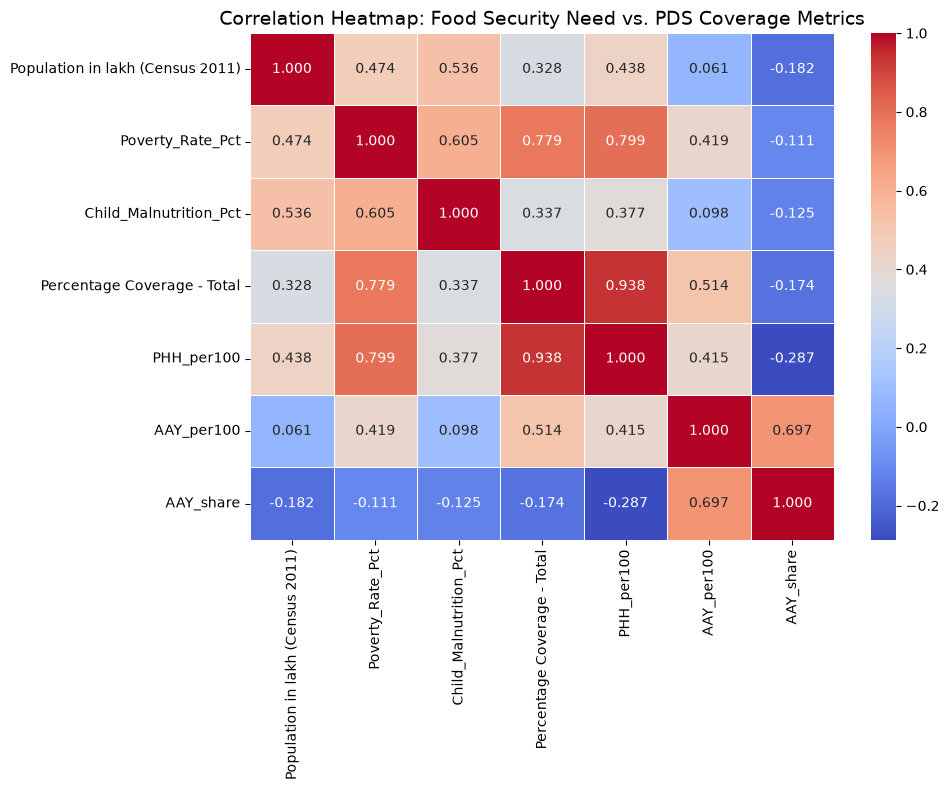

In [6]:
# 1. Select key variables for correlation analysis
correlation_cols = [
    'Population in lakh (Census 2011)',
    'Poverty_Rate_Pct',
    'Child_Malnutrition_Pct',
    'Percentage Coverage - Total',
    # [CHANGE 6] the two absolute-count columns (correlation about 1.0 with population, no information) are replaced by the AAY/PHH ratio features
    'PHH_per100',
    'AAY_per100',
    'AAY_share'
]

# Calculate correlation matrix
corr_matrix = clean_pds_df[correlation_cols].corr()

print("--- Correlation Matrix Between Need and Coverage Metrics ---")
display(corr_matrix.round(3))

# 2. Plotting the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.5)
plt.title('Correlation Heatmap: Food Security Need vs. PDS Coverage Metrics', fontsize=14)
plt.tight_layout()
plt.savefig('outputs/figures/fig2_correlation.png', dpi=200, bbox_inches='tight')  # [ADDED 7] save figure for the report
plt.show()

## Descriptive Statistics & Distributions
A summary table and histograms of the main variables, plus Pearson and Spearman correlations between need and coverage (Spearman is robust to outliers).

<!-- ADDED 6: new section. Remove this comment. -->

,Variable,N,Mean,SD,Min,Median,Max
0,MPI headcount (%),36,17.44,12.90,0.71,14.30,51.91
1,Child underweight (%),36,25.82,8.36,9.10,25.70,41.00
2,Total coverage (%),36,60.98,15.28,16.65,62.63,87.74
3,PHH persons per 100 pop.,36,51.44,14.13,12.11,52.52,71.88
4,AAY persons per 100 pop.,36,7.14,3.07,0.09,7.37,12.59
5,AAY share of covered (%),36,12.36,5.43,0.33,11.35,26.77
6,Population (lakh),36,336.20,430.14,0.64,210.53,1995.81


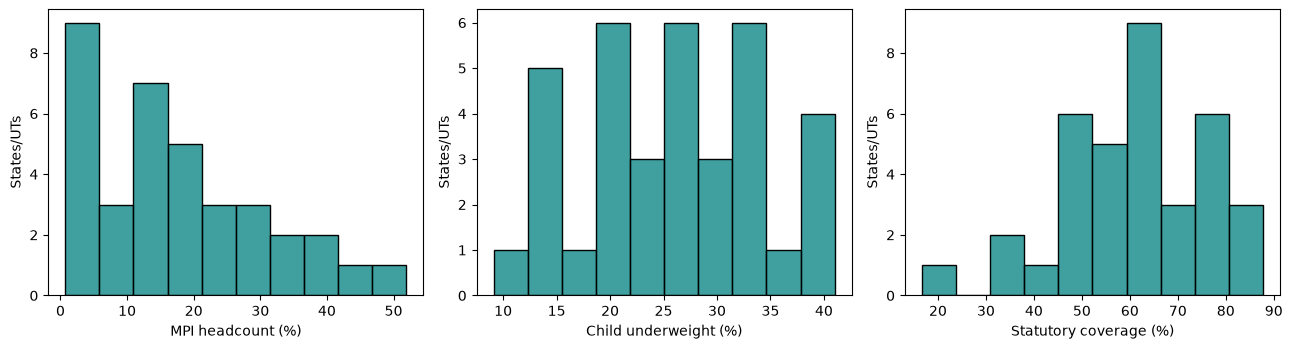

Poverty_Rate_Pct vs Child_Malnutrition_Pct: Pearson r = 0.605 (p = 9.3e-05), Spearman rho = 0.635
Poverty_Rate_Pct vs Percentage Coverage - Total: Pearson r = 0.779 (p = 2.3e-08), Spearman rho = 0.836
Child_Malnutrition_Pct vs Percentage Coverage - Total: Pearson r = 0.337 (p = 0.045), Spearman rho = 0.435


In [7]:
# [ADDED 6] descriptive statistics, distributions and correlation tests
desc = clean_pds_df[[P, M, Y, 'PHH_per100', 'AAY_per100', 'AAY_share', POP]].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].reset_index()
desc.columns = ['Variable', 'N', 'Mean', 'SD', 'Min', 'Median', 'Max']
desc['Variable'] = ['MPI headcount (%)', 'Child underweight (%)', 'Total coverage (%)', 'PHH persons per 100 pop.', 'AAY persons per 100 pop.', 'AAY share of covered (%)', 'Population (lakh)']
desc['N'] = desc['N'].astype(int)
display(desc.round(2))
desc.round(4).to_csv('outputs/tables/descriptives.csv', index=False)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (c, t) in zip(ax, [(P, 'MPI headcount (%)'), (M, 'Child underweight (%)'), (Y, 'Statutory coverage (%)')]):
    sns.histplot(clean_pds_df[c], bins=10, ax=a, color='teal')
    a.set_xlabel(t)
    a.set_ylabel('States/UTs')
plt.tight_layout()
plt.savefig('outputs/figures/fig1_distributions.png', dpi=200, bbox_inches='tight')
plt.show()

from scipy import stats
for k, (a, b) in {'pm': (P, M), 'py': (P, Y), 'my': (M, Y)}.items():
    r_, p_ = stats.pearsonr(clean_pds_df[a], clean_pds_df[b])
    rho_, prho_ = stats.spearmanr(clean_pds_df[a], clean_pds_df[b])
    results[f'r_{k}'], results[f'rho_{k}'] = float(r_), float(rho_)
    print(f"{a} vs {b}: Pearson r = {r_:.3f} (p = {p_:.2g}), Spearman rho = {rho_:.3f}")

### **Bivariate Trend Analysis**
Before building our predictive model, we visualize the direct relationship between our primary independent variable (`Poverty_Rate_Pct`) and PDS Coverage with an exploratory regression trendline. This visually maps how progressively the PDS targets rise as state-level poverty increases.

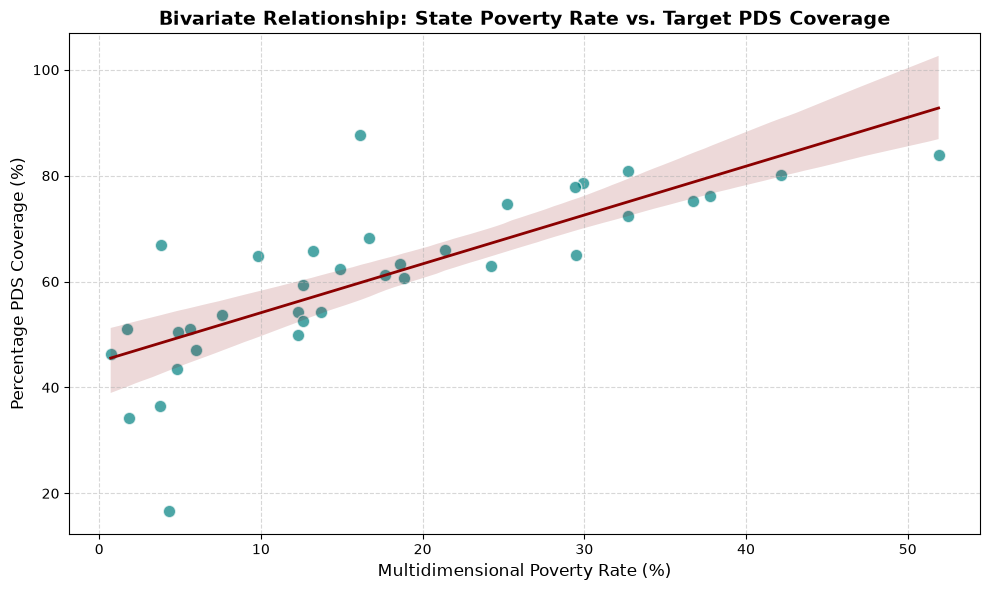

In [8]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=clean_pds_df,
    x='Poverty_Rate_Pct',
    y='Percentage Coverage - Total',
    color='teal',
    scatter_kws={'s': 80, 'alpha': 0.7, 'edgecolor': 'w'},
    line_kws={'color': 'darkred', 'lw': 2}
)
plt.title('Bivariate Relationship: State Poverty Rate vs. Target PDS Coverage', fontsize=14, weight='bold')
plt.xlabel('Multidimensional Poverty Rate (%)', fontsize=12)
plt.ylabel('Percentage PDS Coverage (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('outputs/figures/fig3_scatter.png', dpi=200, bbox_inches='tight')  # [ADDED 7] save figure for the report
plt.show()

##  Predictive Regression Modeling & Residual Analysis
We build a Multiple Linear Regression model using our need indicators (`Poverty_Rate_Pct` and `Child_Malnutrition_Pct`) to predict the expected legal target coverage (`Percentage Coverage - Total`).

By measuring the model's **residuals** (Actual Coverage $-$ Predicted Coverage), we will identify:
1. **Under-covered States (Negative Residuals):** States whose actual coverage is lower than their poverty and malnutrition rates would justify.
2. **Over-covered States (Positive Residuals):** States with coverage higher than predicted by their objective need metrics.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# 1. Define independent variables (Features representing 'Need') and target variable (PDS Coverage)
X = clean_pds_df[['Poverty_Rate_Pct', 'Child_Malnutrition_Pct']]
y = clean_pds_df['Percentage Coverage - Total']

# 2. Fit the Linear Regression Model
model = LinearRegression()
model.fit(X, y)

# 3. Generate predictions
clean_pds_df['Predicted_Coverage_Pct'] = model.predict(X)

# Calculate Residuals (Actual - Predicted)
clean_pds_df['Residual'] = clean_pds_df['Percentage Coverage - Total'] - clean_pds_df['Predicted_Coverage_Pct']

# 4. Model performance stats
r2 = r2_score(y, clean_pds_df['Predicted_Coverage_Pct'])
mse = mean_squared_error(y, clean_pds_df['Predicted_Coverage_Pct'])
rmse = np.sqrt(mse)

print("--- Model Evaluation Statistics (in-sample: fitted and scored on the same 36 rows) ---")  # [CHANGE 7] label only; see the leave-one-out section below for out-of-sample scores
print(f"R-squared Score (Variance Explained): {r2:.4f} ({r2*100:.2f}%)")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}%")
print(f"Intercept (Beta_0): {model.intercept_:.4f}")
print(f"Coefficient for Poverty Rate (Beta_1): {model.coef_[0]:.4f}")
print(f"Coefficient for Malnutrition (Beta_2): {model.coef_[1]:.4f}")

--- Model Evaluation Statistics (in-sample: fitted and scored on the same 36 rows) ---
R-squared Score (Variance Explained): 0.6348 (63.48%)
Root Mean Squared Error (RMSE): 9.1050%
Intercept (Beta_0): 52.2430
Coefficient for Poverty Rate (Beta_1): 1.0745
Coefficient for Malnutrition (Beta_2): -0.3875


## Statistical Inference, Multicollinearity & Nested Test
The model above only reports point estimates. Here we add standard errors, confidence intervals, robust (HC3) p-values, the variance inflation factor (VIF), and a nested F-test of whether child malnutrition adds anything beyond poverty.

<!-- ADDED 8: new section. Remove this comment. -->

In [10]:
# [ADDED 8] OLS with statsmodels for inference (same model as above)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X2 = clean_pds_df[[P, M]].reset_index(drop=True)
y2 = clean_pds_df[Y].reset_index(drop=True)
Xc = sm.add_constant(X2)
ols_full = sm.OLS(y2, Xc).fit()
ols_pov = sm.OLS(y2, sm.add_constant(X2[[P]])).fit()     # poverty-only comparison model
hc3 = ols_full.get_robustcov_results('HC3')
ci = ols_full.conf_int()
coef = pd.DataFrame({'Term': ['Intercept', 'MPI headcount (pp)', 'Child underweight (pp)'],
                     'Coef': ols_full.params.values, 'SE': ols_full.bse.values, 't': ols_full.tvalues.values,
                     'p': ols_full.pvalues.values, 'p (HC3 robust)': np.asarray(hc3.pvalues),
                     'CI low': ci[0].values, 'CI high': ci[1].values})
print("--- OLS coefficients with inference ---")
display(coef.round(4))
coef.round(4).to_csv('outputs/tables/ols_coefficients.csv', index=False)

results['r2_both'], results['adjr2_both'] = float(ols_full.rsquared), float(ols_full.rsquared_adj)
results['r2_pov'], results['adjr2_pov'] = float(ols_pov.rsquared), float(ols_pov.rsquared_adj)
results['F'], results['F_p'] = float(ols_full.fvalue), float(ols_full.f_pvalue)
F12, p12, _ = ols_full.compare_f_test(ols_pov)           # does malnutrition add anything beyond poverty?
results['nested_F'], results['nested_p'] = float(F12), float(p12)
results['vif'] = float(variance_inflation_factor(Xc.values, 1))
ci1 = ols_pov.conf_int()
results['b_pov_only'], results['p_pov_only'] = float(ols_pov.params[P]), float(ols_pov.pvalues[P])
results['b_pov_only_ci'] = [float(ci1.loc[P, 0]), float(ci1.loc[P, 1])]
print(f"\nR2 both = {results['r2_both']:.4f} (adjusted {results['adjr2_both']:.4f}); poverty only = {results['r2_pov']:.4f} (adjusted {results['adjr2_pov']:.4f})")
print(f"Overall F = {results['F']:.2f}, p = {results['F_p']:.2g}")
print(f"Adding malnutrition beyond poverty: F = {results['nested_F']:.3f}, p = {results['nested_p']:.3f}")
print(f"VIF between the two predictors = {results['vif']:.2f}")

--- OLS coefficients with inference ---


,Term,Coef,SE,t,p,p (HC3 robust),CI low,CI high
0,Intercept,52.2430,5.3128,9.8334,0.0000,0.000,41.4340,63.0520
1,MPI headcount (pp),1.0745,0.1566,6.8637,0.0000,0.000,0.7560,1.3931
2,Child underweight (pp),-0.3875,0.2414,-1.6048,0.1181,0.219,-0.8787,0.1037



R2 both = 0.6348 (adjusted 0.6126); poverty only = 0.6063 (adjusted 0.5947)
Overall F = 28.68, p = 6.1e-08
Adding malnutrition beyond poverty: F = 2.576, p = 0.118
VIF between the two predictors = 1.58


In [11]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

# 1. Scale features for Ridge Regression
scaler_reg = StandardScaler()
X_scaled_reg = scaler_reg.fit_transform(X)

# 2. Fit Classical Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_scaled_reg, y)
ols_preds = ols_model.predict(X_scaled_reg)

# 3. Fit Ridge Regression (with default alpha=1.0)
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_scaled_reg, y)
ridge_preds = ridge_model.predict(X_scaled_reg)

# 4. Compute comparative metrics
metrics_dict = {
    'Metric': ['R-squared (R2)', 'Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)'],
    'Ordinary Least Squares (OLS)': [
        r2_score(y, ols_preds),
        np.sqrt(mean_squared_error(y, ols_preds)),
        mean_absolute_error(y, ols_preds)
    ],
    'Ridge Regression (L2)': [
        r2_score(y, ridge_preds),
        np.sqrt(mean_squared_error(y, ridge_preds)),
        mean_absolute_error(y, ridge_preds)
    ]
}

comparison_df = pd.DataFrame(metrics_dict)
print("--- Model Comparison: OLS vs. Ridge Regression ---")
display(comparison_df.round(4))

# Print coefficients for both
print("\n--- Model Coefficients (Standardized) ---")
print(f"OLS Coefficients: Poverty = {ols_model.coef_[0]:.4f}, Malnutrition = {ols_model.coef_[1]:.4f}")
print(f"Ridge Coefficients: Poverty = {ridge_model.coef_[0]:.4f}, Malnutrition = {ridge_model.coef_[1]:.4f}")

# [ADDED 8] keep the standardized coefficients for the report (code above unchanged; note these metrics are also in-sample and alpha=1.0 is tuned in the CV section below)
results['std_ols'] = ols_model.coef_.tolist()
results['std_ridge'] = ridge_model.coef_.tolist()

--- Model Comparison: OLS vs. Ridge Regression ---


,Metric,Ordinary Least Squares (OLS),Ridge Regression (L2)
0,R-squared (R2),0.6348,0.6336
1,Root Mean Squared Error (RMSE),9.1050,9.1197
2,Mean Absolute Error (MAE),6.7194,6.5885



--- Model Coefficients (Standardized) ---
OLS Coefficients: Poverty = 13.6634, Malnutrition = -3.1947
Ridge Coefficients: Poverty = 13.0205, Malnutrition = -2.7299


## Out-of-Sample Validation (Leave-One-Out) with Baselines
The OLS/Ridge metrics above are computed on the same 36 rows used for fitting. With only 36 States/UTs, a single train/test split is unstable, so we score every model by **leave-one-out cross-validation (LOOCV)** and compare against a mean-only baseline and a poverty-only model. The Ridge penalty is also tuned by cross-validation, and a bootstrap shows whether Ridge really reduces coefficient variability.

<!-- ADDED 9: new section. Remove this comment. -->

In [12]:
# [ADDED 9] leave-one-out validation (scaling and alpha search are refit inside every fold, so there is no leakage)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline

Xall = clean_pds_df[[P, M, 'LogPop']].reset_index(drop=True)
specs = {
    'Mean-only baseline': (DummyRegressor(strategy='mean'), [P]),
    'OLS: poverty only': (make_pipeline(StandardScaler(), LinearRegression()), [P]),
    'OLS: poverty + underweight': (make_pipeline(StandardScaler(), LinearRegression()), [P, M]),
    'OLS: poverty + underweight + log population': (make_pipeline(StandardScaler(), LinearRegression()), [P, M, 'LogPop']),
    'Ridge (alpha = 1.0)': (make_pipeline(StandardScaler(), Ridge(alpha=1.0)), [P, M]),
    'Ridge (alpha tuned by LOO-CV)': (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 60))), [P, M]),
}
rows = []
for name, (mdl, cols) in specs.items():
    pred = cross_val_predict(mdl, Xall[cols], y2, cv=LeaveOneOut())
    mdl.fit(Xall[cols], y2)
    ins = mdl.predict(Xall[cols])
    rows.append([name, r2_score(y2, pred), float(np.sqrt(mean_squared_error(y2, pred))), mean_absolute_error(y2, pred),
                 r2_score(y2, ins), float(np.sqrt(mean_squared_error(y2, ins)))])
cv_table = pd.DataFrame(rows, columns=['Model', 'LOO R2', 'LOO RMSE', 'LOO MAE', 'In-sample R2', 'In-sample RMSE'])
print("--- Leave-one-out validation vs baselines ---")
display(cv_table.round(3))
cv_table.round(4).to_csv('outputs/tables/validation_loo.csv', index=False)
results['alpha_cv'] = float(specs['Ridge (alpha tuned by LOO-CV)'][0].named_steps['ridgecv'].alpha_)
print("Ridge alpha chosen on the full data:", results['alpha_cv'])

# bootstrap: does Ridge (alpha = 1) really reduce coefficient variance compared with OLS?
rng = np.random.default_rng(SEED)
bo, br = [], []
for _ in range(2000):
    i = rng.integers(0, len(y2), len(y2))
    bo.append(LinearRegression().fit(X_scaled_reg[i], y2.iloc[i]).coef_)
    br.append(Ridge(alpha=1.0).fit(X_scaled_reg[i], y2.iloc[i]).coef_)
bo, br = np.array(bo), np.array(br)
boot = pd.DataFrame({
    'Coefficient': ['MPI (per SD)', 'Underweight (per SD)'],
    'OLS estimate': ols_model.coef_, 'OLS boot SD': bo.std(0),
    'OLS 95% CI': [f"[{np.percentile(bo[:, j], 2.5):.1f}, {np.percentile(bo[:, j], 97.5):.1f}]" for j in range(2)],
    'Ridge estimate': ridge_model.coef_, 'Ridge boot SD': br.std(0),
    'Ridge 95% CI': [f"[{np.percentile(br[:, j], 2.5):.1f}, {np.percentile(br[:, j], 97.5):.1f}]" for j in range(2)]})
print("\n--- Bootstrap (2000 resamples): OLS vs Ridge ---")
display(boot.round(2))
boot.round(4).to_csv('outputs/tables/bootstrap_ols_vs_ridge.csv', index=False)
results['sd_mpi'] = float(X2[P].std(ddof=0))

--- Leave-one-out validation vs baselines ---


,Model,LOO R2,LOO RMSE,LOO MAE,In-sample R2,In-sample RMSE
0,Mean-only baseline,-0.058,15.496,12.244,0.000,15.066
1,OLS: poverty only,0.559,10.004,6.865,0.606,9.454
2,OLS: poverty + underweight,0.556,10.035,7.409,0.635,9.105
3,OLS: poverty + underweight + log population,0.554,10.065,7.664,0.657,8.821
4,Ridge (alpha = 1.0),0.559,10.001,7.238,0.634,9.120
5,Ridge (alpha tuned by LOO-CV),0.559,10.004,7.160,0.631,9.148


Ridge alpha chosen on the full data: 1.795714494371641

--- Bootstrap (2000 resamples): OLS vs Ridge ---


,Coefficient,OLS estimate,OLS boot SD,OLS 95% CI,Ridge estimate,Ridge boot SD,Ridge 95% CI
0,MPI (per SD),13.66,2.19,"[10.1, 18.6]",13.02,2.02,"[9.6, 17.4]"
1,Underweight (per SD),-3.19,2.32,"[-8.2, 0.7]",-2.73,2.14,"[-7.2, 0.9]"


### Visualizing the Residual Gaps
Let's sort the states by their residuals to isolate which states have the largest targeting gaps (negative residuals) or excess capacity (positive residuals) compared to their socio-economic needs.

--- Top 5 Under-Covered States/UTs (Negative Residuals) ---


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual
29,Andaman and Nicobar,4.30,23.7,16.65,47.680351,-31.030351
6,Goa,3.76,24.0,36.50,46.983854,-10.483854
31,Lakshadweep,1.82,25.8,34.17,44.201778,-10.031778
35,Ladakh,12.58,9.1,52.47,62.234743,-9.764743
1,Arunachal Pradesh,24.20,15.4,62.95,72.279862,-9.329862



--- Top 5 Over-Covered States/UTs (Positive Residuals) ---


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual
25,Tripura,16.70,25.6,68.15,60.268512,7.881488
14,Maharashtra,14.90,36.1,62.31,54.265828,8.044172
11,Karnataka,13.20,32.9,65.75,53.679025,12.070975
22,Sikkim,3.82,13.1,66.87,51.271818,15.598182
15,Manipur,16.10,13.3,87.74,64.389743,23.350257


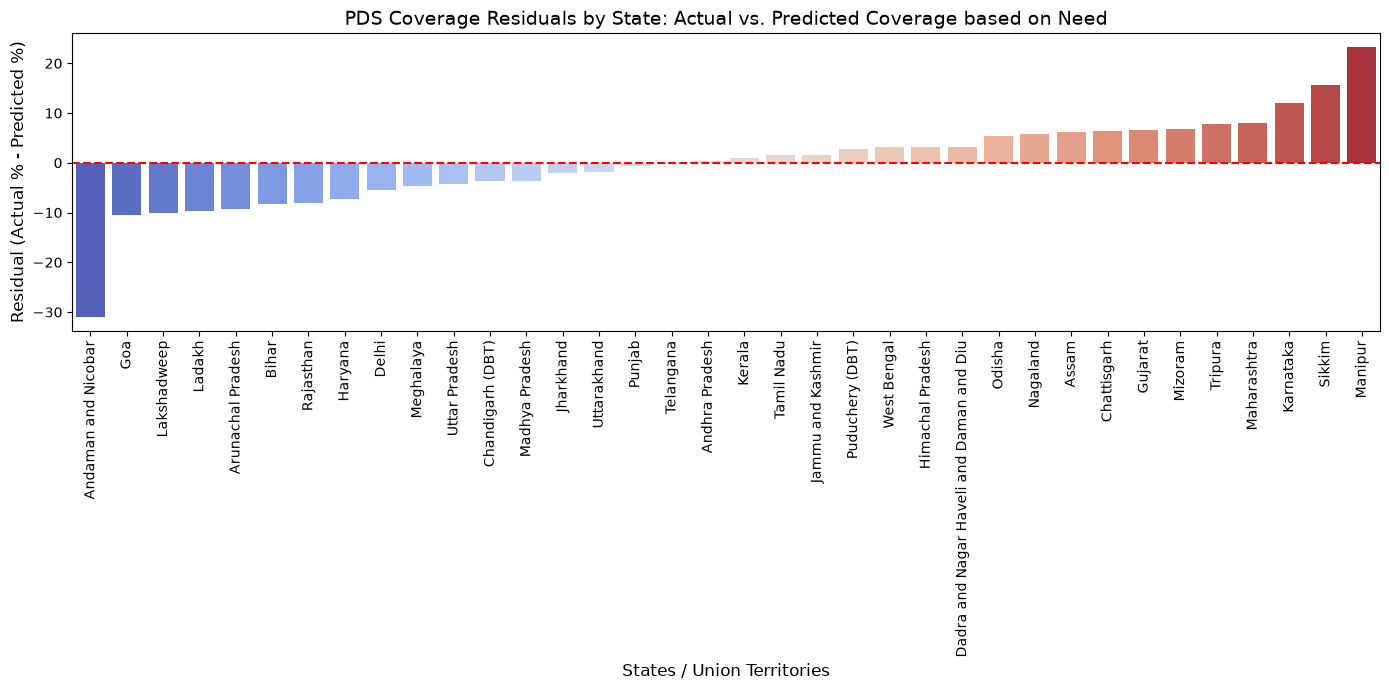

In [13]:
# Sort states by residual values to identify mismatch extremes
residuals_df = clean_pds_df[['States/ UTs', 'Poverty_Rate_Pct', 'Child_Malnutrition_Pct', 'Percentage Coverage - Total', 'Predicted_Coverage_Pct', 'Residual']].copy()
residuals_df = residuals_df.sort_values(by='Residual')

print("--- Top 5 Under-Covered States/UTs (Negative Residuals) ---")
display(residuals_df.head(5))

print("\n--- Top 5 Over-Covered States/UTs (Positive Residuals) ---")
display(residuals_df.tail(5))

# Plotting Residuals across all States/UTs
plt.figure(figsize=(14, 7))
sns.barplot(data=residuals_df, x='States/ UTs', y='Residual', hue='States/ UTs', palette='coolwarm', legend=False)  # [CHANGE 8] hue added only to silence a seaborn deprecation warning; same plot
plt.xticks(rotation=90)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title('PDS Coverage Residuals by State: Actual vs. Predicted Coverage based on Need', fontsize=14)
plt.ylabel('Residual (Actual % - Predicted %)', fontsize=12)
plt.xlabel('States / Union Territories', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/figures/fig_residuals_raw.png', dpi=200, bbox_inches='tight')  # [ADDED 7] save figure for the report
plt.show()

## Residual Z-Scores & Diagnostics
Raw residuals depend on the model's error scale. The problem statement asks for **residual z-scores**, so we compute studentised residuals (a State is flagged when |z| > 2), Cook's distance, and standard residual tests (Breusch-Pagan for equal variance, Shapiro-Wilk for normality).

<!-- ADDED 10: new section. Remove this comment. -->

Breusch-Pagan p = 0.383 | Shapiro-Wilk p = 0.051
Residuals sum to 0.000000 (zero by construction when an intercept is fitted)
States/UTs with |residual z-score| > 2: ['Manipur', 'Andaman and Nicobar']


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual,Studentised_Residual,Cooks_Distance
29,Andaman and Nicobar,4.30,23.7,16.65,47.68,-31.03,-4.10,0.26
6,Goa,3.76,24.0,36.50,46.98,-10.48,-1.15,0.03
31,Lakshadweep,1.82,25.8,34.17,44.20,-10.03,-1.11,0.04
35,Ladakh,12.58,9.1,52.47,62.23,-9.76,-1.13,0.09
1,Arunachal Pradesh,24.20,15.4,62.95,72.28,-9.33,-1.06,0.06


,States/ UTs,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,Predicted_Coverage_Pct,Residual,Studentised_Residual,Cooks_Distance
25,Tripura,16.70,25.6,68.15,60.27,7.88,0.84,0.01
14,Maharashtra,14.90,36.1,62.31,54.27,8.04,0.89,0.03
11,Karnataka,13.20,32.9,65.75,53.68,12.07,1.34,0.05
22,Sikkim,3.82,13.1,66.87,51.27,15.60,1.78,0.10
15,Manipur,16.10,13.3,87.74,64.39,23.35,2.90,0.31


Poverty-only OLS without flagged units: slope = 0.854, R2 = 0.750, N = 34


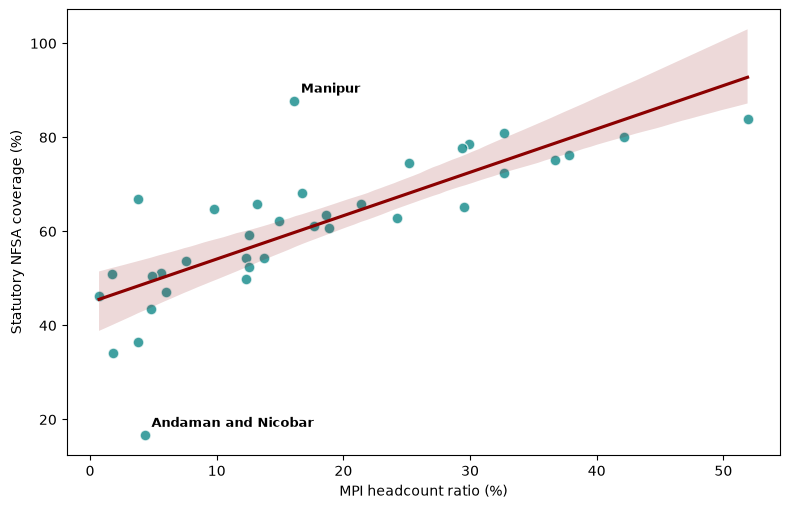

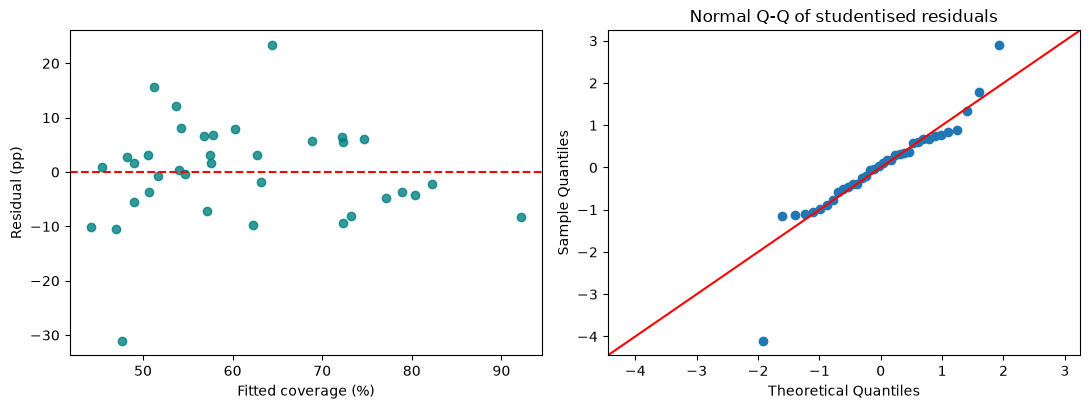

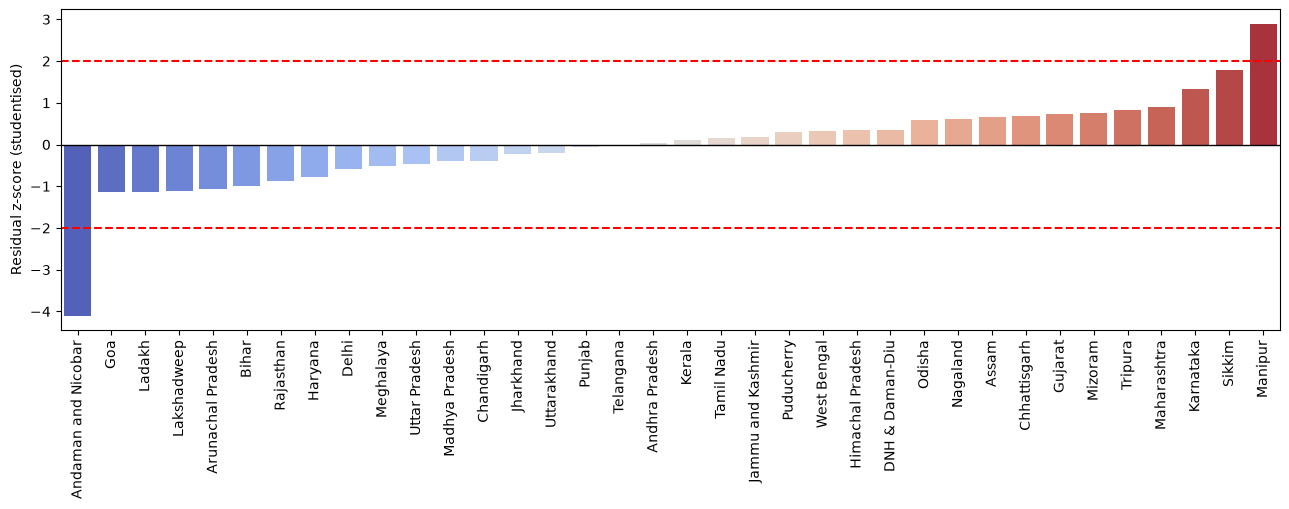

In [14]:
# [ADDED 10] residual z-scores (studentised residuals), influence and diagnostic tests for the two-predictor OLS
from statsmodels.stats.diagnostic import het_breuschpagan

infl = ols_full.get_influence()
clean_pds_df['Studentised_Residual'] = infl.resid_studentized_external
clean_pds_df['Cooks_Distance'] = infl.cooks_distance[0]
clean_pds_df['Leverage'] = infl.hat_matrix_diag
results['bp_p'] = float(het_breuschpagan(ols_full.resid, Xc)[1])
results['shapiro_p'] = float(stats.shapiro(ols_full.resid).pvalue)
results['resid_sum'] = float(clean_pds_df['Residual'].sum())
results['rmse_insample'] = float(np.sqrt(np.mean(clean_pds_df['Residual'] ** 2)))
results['n_cooks_gt_4n'] = int((clean_pds_df['Cooks_Distance'] > 4 / len(clean_pds_df)).sum())
flag = clean_pds_df['Studentised_Residual'].abs() > 2
results['flagged'] = clean_pds_df.loc[flag, STATE].tolist()
print(f"Breusch-Pagan p = {results['bp_p']:.3f} | Shapiro-Wilk p = {results['shapiro_p']:.3f}")
print(f"Residuals sum to {results['resid_sum']:.6f} (zero by construction when an intercept is fitted)")
print("States/UTs with |residual z-score| > 2:", results['flagged'])
cols_show = [STATE, P, M, Y, 'Predicted_Coverage_Pct', 'Residual', 'Studentised_Residual', 'Cooks_Distance']
display(clean_pds_df.sort_values('Residual')[cols_show].round(2).head(5))
display(clean_pds_df.sort_values('Residual')[cols_show].round(2).tail(5))

if flag.any():   # robustness: refit the poverty-only model without the flagged units
    sub_df = clean_pds_df[~flag]
    s1 = sm.OLS(sub_df[Y], sm.add_constant(sub_df[[P]])).fit()
    results['sens_slope'], results['sens_r2'], results['sens_n'] = float(s1.params[P]), float(s1.rsquared), int(len(sub_df))
    print(f"Poverty-only OLS without flagged units: slope = {results['sens_slope']:.3f}, R2 = {results['sens_r2']:.3f}, N = {results['sens_n']}")

# figure: scatter with the flagged units labelled
fig, ax = plt.subplots(figsize=(8, 5.2))
sns.regplot(data=clean_pds_df, x=P, y=Y, ax=ax, color='teal', scatter_kws={'s': 60, 'alpha': .75, 'edgecolor': 'w'}, line_kws={'color': 'darkred'})
for _, r in clean_pds_df[flag].iterrows():
    ax.annotate(r[STATE].replace(' (DBT)', ''), (r[P], r[Y]), xytext=(5, 6), textcoords='offset points', fontsize=9, weight='bold')
ax.set_xlabel('MPI headcount ratio (%)')
ax.set_ylabel('Statutory NFSA coverage (%)')
plt.tight_layout()
plt.savefig('outputs/figures/fig3_scatter_flagged.png', dpi=200, bbox_inches='tight')
plt.show()

# figure: residual diagnostics
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(clean_pds_df['Predicted_Coverage_Pct'], clean_pds_df['Residual'], color='teal', alpha=.8)
ax[0].axhline(0, color='red', ls='--')
ax[0].set_xlabel('Fitted coverage (%)')
ax[0].set_ylabel('Residual (pp)')
sm.qqplot(clean_pds_df['Studentised_Residual'], line='45', ax=ax[1])
ax[1].set_title('Normal Q-Q of studentised residuals')
plt.tight_layout()
plt.savefig('outputs/figures/fig4_diagnostics.png', dpi=200, bbox_inches='tight')
plt.show()

# figure: residual z-score by State/UT
d5 = clean_pds_df.sort_values('Studentised_Residual').copy()
d5['Unit'] = d5[STATE].str.replace('Dadra and Nagar Haveli and Daman and Diu', 'DNH & Daman-Diu').str.replace(' (DBT)', '', regex=False).str.replace('Puduchery', 'Puducherry').str.replace('Chattisgarh', 'Chhattisgarh')
plt.figure(figsize=(13, 5.2))
sns.barplot(data=d5, x='Unit', y='Studentised_Residual', hue='Unit', palette='coolwarm', legend=False)
plt.axhline(0, color='k', lw=1)
plt.axhline(2, color='red', ls='--')
plt.axhline(-2, color='red', ls='--')
plt.xticks(rotation=90)
plt.ylabel('Residual z-score (studentised)')
plt.xlabel('')
plt.tight_layout()
plt.savefig('outputs/figures/fig5_residual_zscores.png', dpi=200, bbox_inches='tight')
plt.show()

## AAY and PHH Separately
The same validation and residual z-score flagging is repeated for four outcomes: total coverage, PHH coverage, AAY coverage (both per 100 population) and the AAY share of covered persons.

<!-- ADDED 11: new section. Remove this comment. -->

In [15]:
# [ADDED 11] tier-specific analysis (same method for every outcome)
OUTCOMES = {'total': ('Total coverage (% of population)', Y),
            'phh': ('PHH coverage (persons per 100 population)', 'PHH_per100'),
            'aay': ('AAY coverage (persons per 100 population)', 'AAY_per100'),
            'share': ('AAY share of covered persons (%)', 'AAY_share')}
def pf(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'

tier, rows2, rows3 = {}, [], []
for key, (label, col) in OUTCOMES.items():
    yy = clean_pds_df[col].reset_index(drop=True)
    r2, rm = {}, {}
    for k, (mdl, cols) in {'base': (DummyRegressor(), [P]),
                           'pov': (make_pipeline(StandardScaler(), LinearRegression()), [P]),
                           'both': (make_pipeline(StandardScaler(), LinearRegression()), [P, M])}.items():
        pr = cross_val_predict(mdl, X2[cols], yy, cv=LeaveOneOut())
        r2[k], rm[k] = float(r2_score(yy, pr)), float(np.sqrt(mean_squared_error(yy, pr)))
    o1 = sm.OLS(yy, sm.add_constant(X2[[P]])).fit()
    o2 = sm.OLS(yy, Xc).fit()
    pn = float(o2.compare_f_test(o1)[1])
    c1 = o1.conf_int()
    st = pd.Series(o2.get_influence().resid_studentized_external)
    below = [f"{clean_pds_df.loc[i, STATE].replace(' (DBT)', '')} ({st[i]:+.1f})" for i in st[st < -2].sort_values().index]
    above = [f"{clean_pds_df.loc[i, STATE].replace(' (DBT)', '')} ({st[i]:+.1f})" for i in st[st > 2].sort_values(ascending=False).index]
    tier[key] = dict(label=label, loo_r2_base=r2['base'], loo_r2_pov=r2['pov'], loo_r2_both=r2['both'], loo_rmse_pov=rm['pov'],
                     slope=float(o1.params[P]), slope_lo=float(c1.loc[P, 0]), slope_hi=float(c1.loc[P, 1]),
                     slope_p=float(o1.pvalues[P]), nested_p=pn, below=below, above=above)
    rows2.append([label, round(r2['base'], 2), round(r2['pov'], 2), round(r2['both'], 2),
                  f"{o1.params[P]:.2f} ({c1.loc[P, 0]:.2f} to {c1.loc[P, 1]:.2f})", pf(pn)])
    rows3.append([label, '; '.join(below) or 'none', '; '.join(above) or 'none'])
tier2 = pd.DataFrame(rows2, columns=['Outcome', 'LOO R2: mean only', 'LOO R2: MPI only', 'LOO R2: MPI + underweight',
                                     'MPI slope per point (95% CI)', 'Underweight adds (nested p)'])
tier3 = pd.DataFrame(rows3, columns=['Outcome', 'Below the cross-state pattern (z < -2)', 'Above the pattern (z > 2)'])
display(tier2)
display(tier3)
results['tier'] = tier
tier2.to_csv('outputs/tables/tier_outcomes_validation.csv', index=False)
tier3.to_csv('outputs/tables/tier_outcomes_flagged.csv', index=False)

,Outcome,LOO R2: mean only,LOO R2: MPI only,LOO R2: MPI + underweight,MPI slope per point (95% CI),Underweight adds (nested p)
0,Total coverage (% of population),-0.06,0.56,0.56,0.92 (0.66 to 1.18),0.118
1,PHH coverage (persons per 100 population),-0.06,0.59,0.59,0.88 (0.65 to 1.10),0.198
2,AAY coverage (persons per 100 population),-0.06,0.09,0.09,0.10 (0.02 to 0.18),0.214
3,AAY share of covered persons (%),-0.06,-0.10,-0.14,-0.05 (-0.19 to 0.10),0.674


,Outcome,Below the cross-state pattern (z < -2),Above the pattern (z > 2)
0,Total coverage (% of population),Andaman and Nicobar (-4.1),Manipur (+2.9)
1,PHH coverage (persons per 100 population),Andaman and Nicobar (-3.9),none
2,AAY coverage (persons per 100 population),Chandigarh (-2.3); Rajasthan (-2.1),Tripura (+2.1); Himachal Pradesh (+2.1)
3,AAY share of covered persons (%),Chandigarh (-2.5),Himachal Pradesh (+2.9); Andaman and Nicobar (...


##  K-Means Clustering & Policy Categorization
To group states into distinct strategic policy buckets, we apply unsupervised K-Means clustering using two standardized *need* dimensions:
1. `Poverty_Rate_Pct` (Need)
2. `Child_Malnutrition_Pct` (Need)

Coverage (`Percentage Coverage - Total`) is deliberately **not** used to form the clusters; it is compared across the clusters afterwards.

<!-- CHANGE 9: the clustering originally also used coverage (the outcome), which made the 'need' tiers circular. Remove this comment. -->

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Select and Standardize the features
features_to_cluster = ['Poverty_Rate_Pct', 'Child_Malnutrition_Pct']  # [CHANGE 9] need variables only (coverage removed from the clustering features)
X_cluster = clean_pds_df[features_to_cluster]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 2. Fit K-Means with 3 clusters for easy interpretation
# Setting random_state=42 for deterministic and reproducible cluster results
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=50)  # [CHANGE 9] seed variable and more restarts
clean_pds_df['Cluster'] = kmeans.fit_predict(X_scaled)

# 3. Analyze Cluster Characteristics
cluster_summary = clean_pds_df.groupby('Cluster')[features_to_cluster + ['Percentage Coverage - Total']].mean()  # [CHANGE 9] coverage is now only reported, not clustered on
cluster_counts = clean_pds_df['Cluster'].value_counts().rename('No. of States/UTs')

print("--- Cluster Average Characteristics ---")
display(pd.concat([cluster_summary, cluster_counts], axis=1))

# Assign descriptive names to the clusters based on centroids
# (We will dynamically label them based on their relative poverty levels)
sorted_clusters = cluster_summary['Poverty_Rate_Pct'].sort_values().index.tolist()

cluster_labels = {
    sorted_clusters[0]: "Low Need",        # [CHANGE 9] names no longer pre-judge the coverage level
    sorted_clusters[1]: "Moderate Need",
    sorted_clusters[2]: "High Need"
}

clean_pds_df['Cluster_Name'] = clean_pds_df['Cluster'].map(cluster_labels)
print("\n--- States in Each Policy Cluster ---")
for cluster_id, label in cluster_labels.items():
    states_list = clean_pds_df[clean_pds_df['Cluster'] == cluster_id]['States/ UTs'].tolist()  # [CHANGE 9] all members (the original printed only the first 5)
    print(f"* {label} (n={len(states_list)}): {', '.join(states_list)}")

C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


--- Cluster Average Characteristics ---


,Poverty_Rate_Pct,Child_Malnutrition_Pct,Percentage Coverage - Total,No. of States/UTs
Cluster,,,,
0,8.346111,19.022222,51.976111,18
1,35.862222,32.611111,76.690000,9
2,17.205556,32.611111,63.276667,9



--- States in Each Policy Cluster ---
* Low Need (n=18): Arunachal Pradesh, Delhi, Goa, Haryana, Himachal Pradesh, Kerala, Manipur, Mizoram, Punjab, Sikkim, Tamil Nadu, Uttarakhand, Andaman and Nicobar, Lakshadweep, Chandigarh (DBT), Puduchery (DBT), Jammu and Kashmir, Ladakh
* Moderate Need (n=9): Andhra Pradesh, Gujarat, Karnataka, Maharashtra, Nagaland, Telangana, Tripura, West Bengal, Dadra and Nagar Haveli and Daman and Diu
* High Need (n=9): Assam, Bihar, Chattisgarh, Jharkhand, Madhya Pradesh, Meghalaya, Odisha, Rajasthan, Uttar Pradesh


## Choosing K, Cluster Stability & Coverage by Need Tier
K = 3 was chosen in advance for interpretability. Here we report the elbow and silhouette criteria, check how stable the partition is across random seeds and bootstrap resamples, and compare coverage (and the AAY/PHH ratios) across the need tiers.

<!-- ADDED 12: new section. Remove this comment. -->

C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

 K   WCSS  Silhouette
 2 28.663       0.498
 3 19.452       0.436
 4 14.062       0.420
 5  9.297       0.454
 6  7.028       0.465


C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window


--- Profile of the need tiers ---


C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\lkShy\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Cluster,N,Mean MPI (%),Mean underweight (%),Mean total coverage (%),Mean PHH per 100,Mean AAY per 100,SD total coverage
0,Low Need,18,8.35,19.02,51.98,42.33,6.45,15.08
1,Moderate Need,9,17.21,32.61,63.28,53.23,7.24,6.46
2,High Need,9,35.86,32.61,76.69,67.86,8.42,5.50


Coverage differs across tiers? Kruskal-Wallis p = 0.0001


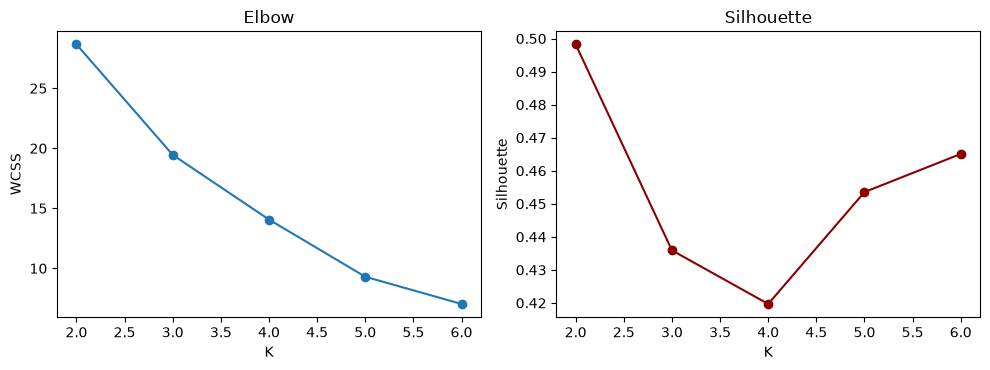

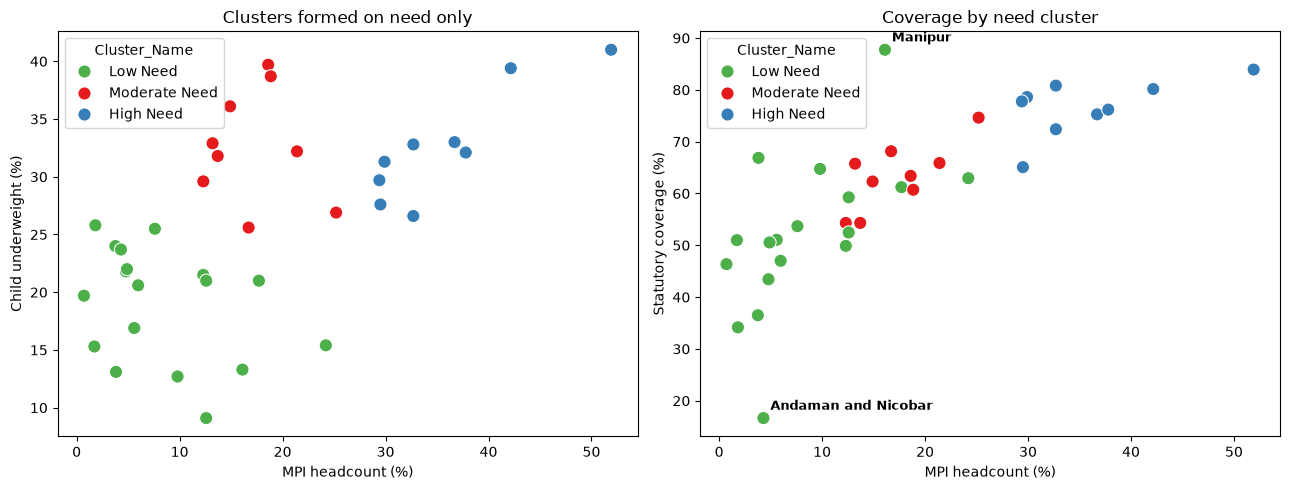

In [17]:
# [ADDED 12] K selection, stability and comparison across tiers
from sklearn.metrics import silhouette_score, adjusted_rand_score

ks = list(range(2, 7))
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=50, random_state=SEED).fit(X_scaled)
    inertia.append(float(km.inertia_))
    sil.append(float(silhouette_score(X_scaled, km.labels_)))
results['k_range'], results['inertia'], results['silhouette'] = ks, inertia, sil
results['best_k'] = ks[int(np.argmax(sil))]
print(pd.DataFrame({'K': ks, 'WCSS': inertia, 'Silhouette': sil}).round(3).to_string(index=False))

base_labels = clean_pds_df['Cluster'].values
aris = [adjusted_rand_score(base_labels, KMeans(3, n_init=1, random_state=s).fit(X_scaled).labels_) for s in range(30)]
rng = np.random.default_rng(SEED)
boot_ari = []
for _ in range(200):
    i = rng.integers(0, len(X_scaled), len(X_scaled))
    kb = KMeans(3, n_init=10, random_state=SEED).fit(X_scaled[i])
    boot_ari.append(adjusted_rand_score(base_labels, kb.predict(X_scaled)))
results['ari_seed_mean'], results['ari_seed_min'] = float(np.mean(aris)), float(np.min(aris))
results['ari_boot_mean'], results['ari_boot_p05'] = float(np.mean(boot_ari)), float(np.percentile(boot_ari, 5))

# for comparison: the original design that also clustered on coverage
X_orig = StandardScaler().fit_transform(clean_pds_df[[P, M, Y]])
orig_labels = KMeans(3, n_init=10, random_state=SEED).fit_predict(X_orig)
results['ari_vs_original'] = float(adjusted_rand_score(base_labels, orig_labels))

levels = ['Low Need', 'Moderate Need', 'High Need']
prof = (clean_pds_df.groupby('Cluster_Name').agg(n=(STATE, 'size'), mpi=(P, 'mean'), mal=(M, 'mean'), cov=(Y, 'mean'),
                                                 phh=('PHH_per100', 'mean'), aay=('AAY_per100', 'mean'), cov_sd=(Y, 'std'))
        .reindex(levels).reset_index())
prof.columns = ['Cluster', 'N', 'Mean MPI (%)', 'Mean underweight (%)', 'Mean total coverage (%)', 'Mean PHH per 100', 'Mean AAY per 100', 'SD total coverage']
print("\n--- Profile of the need tiers ---")
display(prof.round(2))
prof.round(3).to_csv('outputs/tables/cluster_profile.csv', index=False)
results['members'] = {lv: clean_pds_df.loc[clean_pds_df['Cluster_Name'] == lv, STATE].tolist() for lv in levels}
results['cluster_means'] = prof['Mean total coverage (%)'].tolist()
groups = [g[Y].values for _, g in clean_pds_df.groupby('Cluster_Name')]
results['kw_p'] = float(stats.kruskal(*groups).pvalue)
print(f"Coverage differs across tiers? Kruskal-Wallis p = {results['kw_p']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(ks, inertia, 'o-')
ax[0].set_xlabel('K')
ax[0].set_ylabel('WCSS')
ax[0].set_title('Elbow')
ax[1].plot(ks, sil, 'o-', color='darkred')
ax[1].set_xlabel('K')
ax[1].set_ylabel('Silhouette')
ax[1].set_title('Silhouette')
plt.tight_layout()
plt.savefig('outputs/figures/fig7_k_selection.png', dpi=200, bbox_inches='tight')
plt.show()

# figure: need space (clusters) next to coverage by cluster, flagged units labelled
pal = {'Low Need': '#4daf4a', 'Moderate Need': '#e41a1c', 'High Need': '#377eb8'}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=clean_pds_df, x=P, y=M, hue='Cluster_Name', hue_order=levels, palette=pal, s=90, ax=ax[0])
ax[0].set_xlabel('MPI headcount (%)')
ax[0].set_ylabel('Child underweight (%)')
ax[0].set_title('Clusters formed on need only')
sns.scatterplot(data=clean_pds_df, x=P, y=Y, hue='Cluster_Name', hue_order=levels, palette=pal, s=90, ax=ax[1])
for _, r in clean_pds_df[flag].iterrows():
    ax[1].annotate(r[STATE].replace(' (DBT)', ''), (r[P], r[Y]), xytext=(5, 6), textcoords='offset points', fontsize=9, weight='bold')
ax[1].set_xlabel('MPI headcount (%)')
ax[1].set_ylabel('Statutory coverage (%)')
ax[1].set_title('Coverage by need cluster')
plt.tight_layout()
plt.savefig('outputs/figures/fig6_clusters.png', dpi=200, bbox_inches='tight')
plt.show()

### Visualizing the Policy Clusters
Let's plot a 2D scatter plot representing the relationship between Poverty Rate and Actual Coverage, colored by their assigned policy clusters.

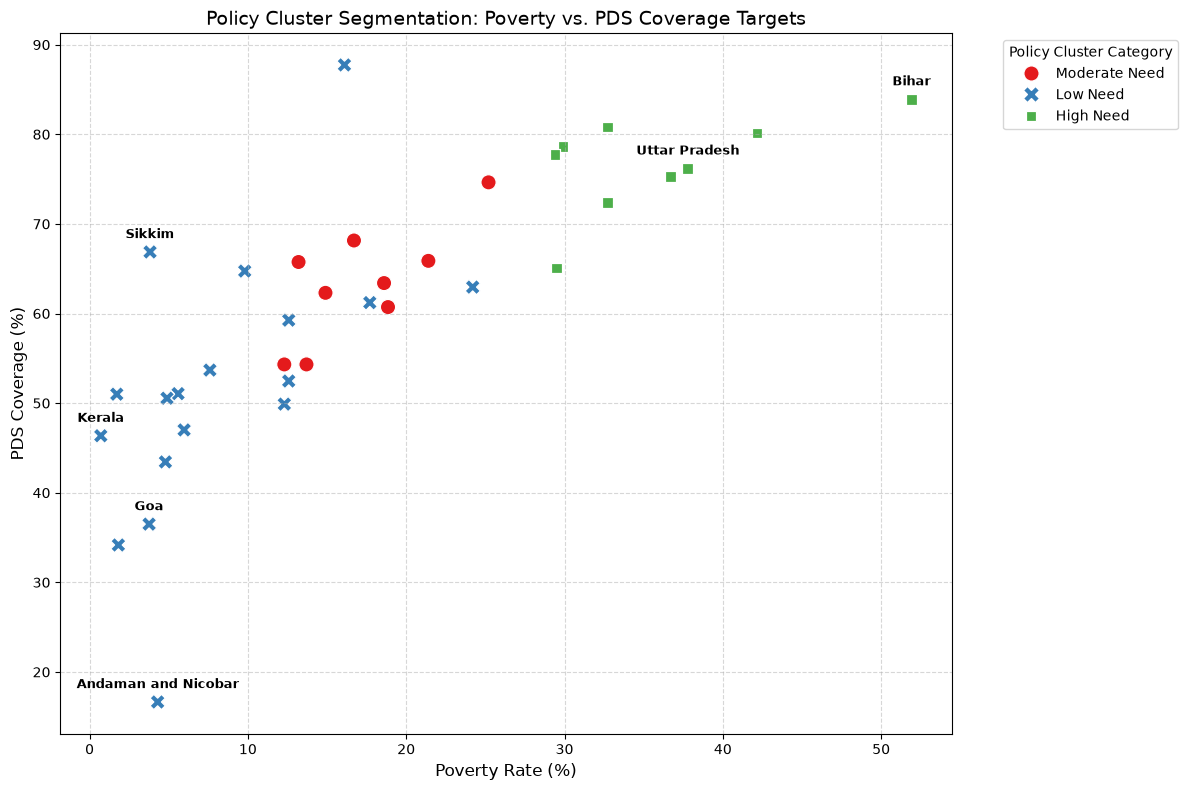

In [18]:
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=clean_pds_df,
    x='Poverty_Rate_Pct',
    y='Percentage Coverage - Total',
    hue='Cluster_Name',
    style='Cluster_Name',
    palette='Set1',
    s=120
)

# Annotate some notable states in the plot
notable_annotations = ['Bihar', 'Kerala', 'Goa', 'Andaman and Nicobar', 'Uttar Pradesh', 'Sikkim']
for idx, row in clean_pds_df.iterrows():
    if row['States/ UTs'] in notable_annotations:
        plt.annotate(
            row['States/ UTs'],
            (row['Poverty_Rate_Pct'], row['Percentage Coverage - Total']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center',
            fontsize=9,
            weight='bold'
        )

plt.title('Policy Cluster Segmentation: Poverty vs. PDS Coverage Targets', fontsize=14)
plt.xlabel('Poverty Rate (%)', fontsize=12)
plt.ylabel('PDS Coverage (%)', fontsize=12)
plt.legend(title='Policy Cluster Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('outputs/figures/fig6_clusters_poverty_coverage.png', dpi=200, bbox_inches='tight')  # [ADDED 7] save figure for the report
plt.show()

## Saving the Results
The key numbers and tables are written to the `outputs/` folder so that the report can quote exactly what this notebook computed.

<!-- ADDED 13: new section. Remove this comment. -->

In [19]:
# [ADDED 13] save the state-level table and all collected numbers
state_cols = [STATE, POP, P, M, Y, 'PHH_per100', 'AAY_per100', 'AAY_share', 'AAY_size', 'Predicted_Coverage_Pct', 'Residual',
              'Studentised_Residual', 'Cooks_Distance', 'Leverage', 'Cluster_Name']
clean_pds_df[state_cols].round(4).to_csv('outputs/tables/state_level_results.csv', index=False)
clean_pds_df.sort_values('Residual')[[STATE, P, M, Y, 'Predicted_Coverage_Pct', 'Residual', 'Studentised_Residual']].round(3).to_csv('outputs/tables/residuals_by_state.csv', index=False)

def _clean(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
with open('outputs/results.json', 'w') as f:
    json.dump(results, f, indent=2, default=_clean)
print("Saved:", sorted(os.listdir('outputs')), sorted(os.listdir('outputs/tables')))

Saved: ['figures', 'report.md', 'report.pdf', 'results.json', 'tables'] ['bootstrap_ols_vs_ridge.csv', 'cluster_membership.csv', 'cluster_profile.csv', 'descriptives.csv', 'ols_coefficients.csv', 'residuals_by_state.csv', 'state_level_results.csv', 'tier_outcomes_flagged.csv', 'tier_outcomes_validation.csv', 'validation_loo.csv']
